# The Section 301 forced-labor tariff: from the surcharge, and from the proposal

Two transitions, one notebook.

1. **Section 122 &rarr; the labor action.** The 10% Section 122 balance-of-payments
   surcharge lapses at 12:01 a.m. on **July 24, 2026**; the Section 301 forced-labor
   action takes effect the same day. What does the swap do to the U.S. import-weighted
   average tariff, and who pays more or less? (This mirrors
   `section122-to-301labor-transition.ipynb`, but with the **final** action now live.)

2. **The proposal &rarr; the final action.** The June 5, 2026 notice was a *proposed*
   action; the July 23, 2026 Notice of Actions is the real one. It is **lighter**: six
   economies were cut from 12.5% to 10%, five moved to a net-of-MFN cap, and a new
   700-code *pharmaceutical* exemption was added. This notebook decomposes the change
   into a **rate effect**, a **net-of-MFN cap effect**, and an **exemption effect**.

All series are produced by the same engine as the published tracker. Per-country rates
match `country-by-time.csv`; national averages add the flat +2.3pp MFN baseline so they
reconcile with the public headline.

In [1]:
# Paths in this notebook are relative to the repository root. Opened from its own
# folder, the notebook moves there first; run from the root, this does nothing.
import os
from pathlib import Path
if not Path("tariff-lists").is_dir():
    os.chdir(next(p for p in Path.cwd().parents if (p / "tariff-lists").is_dir()))

In [2]:
import json, io, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
figfile = "./figures/"
os.makedirs(figfile, exist_ok=True)

plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 2, 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
    'axes.titlesize': 18, 'axes.labelsize': 16,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.frameon': False, 'legend.fontsize': 12,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'savefig.bbox': 'tight',
})

PALETTE = {
    's122':  'black',        # Section 122 in force
    'gap':   '#8B0000',      # post-expiry gap, no labor
    'prov':  '#C8860D',      # provisional labor proposal (Jun 5)
    'final': 'darkblue',     # final labor action (Jul 23, live)
    'up':    '#8B0000',      # rises
    'down':  'darkgreen',    # falls
}

WEIGHT_YEAR  = 2024
WITH_122     = '2026-07-23'   # last day the surcharge is in force
POST_122     = '2026-07-24'   # surcharge gone; labor effective
MFN_BASELINE = 2.3            # flat baseline added to NATIONAL headline only

## Load the tariff engine

Execute the main notebook's code cells up to `tariff_imports`. This imports every mask,
rate function, the action registry, and `_make_stacked_apply` &mdash; the same objects the
published panel is built from. The forced-labor action is now **live** (`LABOR_301_LIVE =
True`), so the loaded `TARIFF_ACTIONS` already contains the final regimes.

In [4]:
_nb = json.load(io.open('code/make-tariff-by-country-by-time.ipynb', encoding='utf-8'))
for _cell in _nb['cells']:
    if _cell['cell_type'] != 'code':
        continue
    _src = ''.join(_cell['source'])
    exec(compile(_src, 'tariff-engine', 'exec'))
    if 'def tariff_imports' in _src:
        break
print(f"engine loaded - {len(TARIFF_ACTIONS)} actions, LABOR_301_LIVE = {LABOR_301_LIVE}")

engine loaded - 89 actions, LABOR_301_LIVE = True


## Build the scenarios

Every scenario is the same engine evaluated with a different action list, swapped into the
global `TARIFF_ACTIONS` that `tariff_imports` reads. Five country-level series at the
transition:

| key | rates | cap | exemptions | meaning |
|-----|-------|-----|------------|---------|
| `s122`  | &mdash; | &mdash; | &mdash; | Section 122 surcharge in force (Jul 23) |
| `gap`   | &mdash; | &mdash; | &mdash; | surcharge expired, no labor (Jul 24) |
| `prov`  | provisional (Jun 5) | flat | provisional Annex A, 1,098 product codes | the proposal |
| `mid`   | **final** | flat | provisional Annex A | final rates, still flat &mdash; isolates the **rate effect** |
| `mid2`  | final | **net-of-MFN** | provisional Annex A | adds the cap for EU/TW/JP/CH &mdash; isolates the **cap effect** |
| `final` | final | net-of-MFN | Annex II Part A (unconditional + pharma, 1,556) | the live action |

`final - prov = (mid - prov) + (mid2 - mid) + (final - mid2) = rate + cap + exemption`.

In [5]:
_cache = {}
def _imp(cty):
    if cty not in _cache:
        _cache[cty] = load_imports(cty, year=WEIGHT_YEAR)
    return _cache[cty].copy()

def rate(cty, date, actions):
    global TARIFF_ACTIONS
    _saved = TARIFF_ACTIONS
    TARIFF_ACTIONS = actions
    try:
        r = tariff_imports(_imp(cty), cty, 0.0, pd.to_datetime(date))
        return (r['tariff'] * r['share']).sum(), r['imports'].sum()
    finally:
        TARIFF_ACTIONS = _saved

# The live action list (final labor), and the same list with labor removed.
ACTIONS_FINAL   = list(TARIFF_ACTIONS)
ACTIONS_NOLABOR = [a for a in TARIFF_ACTIONS
                   if 'forced-labor' not in a.get('reference', '')]

# Provisional exemption list: the 1,098 unflagged product codes only (the model's
# original choice, mirroring Section 122 - aircraft and Ex codes were taxed, and
# there was no pharma bucket).
_prov_ex = pd.read_csv('./tariff-lists/301-labor-exemptions.csv', dtype={'digits': str})
_prov_un = _prov_ex[_prov_ex['scope_limitation'].fillna('') == '']
STACKED_EXEMPT_LISTS['Labor-PROV'] = {
    'hs8':  _prov_un.loc[_prov_un['digits'].str.len() == 8,  'digits'].tolist(),
    'hs10': _prov_un.loc[_prov_un['digits'].str.len() == 10, 'digits'].tolist()}

_CAFTA = {'2230', '2470', '2110', '2050', '2150', '2190'}
def _build_labor(econ_csv, exempt_key, net_cap=False):
    e = pd.read_csv(econ_csv, dtype={'cty_code': str})
    acts = []
    for r in e.itertuples():
        c = str(r.cty_code)
        if c in ('', 'nan'):
            continue
        reg = {'name': f'L-{c}', 'authority': 'Section 301', 'cty_code': c,
               'rate': float(r.proposed_rate_pct), 'effective_date': POST_122,
               'scope': 'all', 'exempt_lists': [exempt_key], 'exempt_232': True,
               'usmca_exempt': c in ('1220', '2010'),
               'cafta_textile_exempt': c in _CAFTA,
               'net_of_mfn': net_cap and c in NET_OF_MFN_CTY}
        acts.append({'effective_date': POST_122, 'authority': 'Section 301',
                     'reference': 'labor-scenario', 'description': '',
                     'phase': 3, 'apply': _make_stacked_apply(reg)})
    return acts

ACTIONS_PROV = ACTIONS_NOLABOR + _build_labor(
    './tariff-lists/301-labor-economies.csv', 'Labor-PROV')                       # prov rates (flat) + prov exempt
ACTIONS_MID  = ACTIONS_NOLABOR + _build_labor(
    './tariff-lists/301-labor-economies-FINAL.csv', 'Labor-PROV')                 # final rates (flat) + prov exempt
ACTIONS_MID2 = ACTIONS_NOLABOR + _build_labor(
    './tariff-lists/301-labor-economies-FINAL.csv', 'Labor-PROV', net_cap=True)   # + net-of-MFN cap (4 non-FTA)

# Country universe, exactly as the engine builds it.
_universe = country_list[['CTY_CODE', 'CTY_NAME']].dropna().drop_duplicates('CTY_CODE')
names = _universe.set_index('CTY_CODE')['CTY_NAME'].to_dict()

rows = []
for c in names:
    try:
        s122, imp = rate(c, WITH_122, ACTIONS_NOLABOR)
    except FileNotFoundError:
        continue
    rows.append(dict(
        code=c, name=names[c].title(), imports=imp / 1e9,
        s122=s122,
        gap=rate(c, POST_122, ACTIONS_NOLABOR)[0],
        prov=rate(c, POST_122, ACTIONS_PROV)[0],
        mid=rate(c, POST_122, ACTIONS_MID)[0],
        mid2=rate(c, POST_122, ACTIONS_MID2)[0],
        final=rate(c, POST_122, ACTIONS_FINAL)[0]))
S = pd.DataFrame(rows)

# tiers and groups
_pe = pd.read_csv('./tariff-lists/301-labor-economies.csv', dtype={'cty_code': str})
_fe = pd.read_csv('./tariff-lists/301-labor-economies-FINAL.csv', dtype={'cty_code': str})
_tier_p = dict(zip(_pe.cty_code.astype(str), _pe.proposed_rate_pct))
_tier_f = dict(zip(_fe.cty_code.astype(str), _fe.proposed_rate_pct))
_targets = {str(x.cty_code) for x in _fe.itertuples() if str(x.cty_code) not in ('', 'nan')}
S['tier_prov']  = S.code.map(_tier_p)
S['tier_final'] = S.code.map(_tier_f)
S['group'] = np.select(
    [S.code.isin(['1220', '2010']), S.code.isin(list(_CAFTA)), S.code.isin(_targets)],
    ['USMCA', 'CAFTA-DR', 'labor target'], default='not targeted')

# labor contributions (over the gap baseline) and the prov->final decomposition
S['prov_contrib']  = S['prov']  - S['gap']
S['final_contrib'] = S['final'] - S['gap']
S['delta']         = S['final'] - S['prov']    # net change, proposal -> final
S['rate_effect']   = S['mid']   - S['prov']    # from the six rate cuts (final rates, flat)
S['cap_effect']    = S['mid2']  - S['mid']     # from the net-of-MFN cap (EU/TW/JP/CH)
S['exempt_effect'] = S['final'] - S['mid2']    # from the pharma / Part A exemptions

def natl(col):
    w = S['imports']
    return (S[col] * w).sum() / w.sum()

NAT = {k: natl(k) + MFN_BASELINE for k in ('s122', 'gap', 'prov', 'mid', 'mid2', 'final')}
print("National import-weighted average effective tariff (incl. +%.1fpp MFN baseline)" % MFN_BASELINE)
for k, lab in [('s122', '122 in force  '), ('gap', '122 gone, no labor'),
               ('prov', 'provisional labor'), ('final', 'FINAL labor   ')]:
    print(f"  {lab}: {NAT[k]:6.2f}%")
print(f"\n  final vs provisional labor: {NAT['final']-NAT['prov']:+.2f} pp national")

National import-weighted average effective tariff (incl. +2.3pp MFN baseline)
  122 in force  :  10.85%
  122 gone, no labor:   7.68%
  provisional labor:  11.72%
  FINAL labor   :  11.19%

  final vs provisional labor: -0.53 pp national


# Part 1 &mdash; Section 122 to the labor action

The surcharge was a flat 10% on (almost) everything; the labor duty is 10&ndash;12.5% on
targeted economies with broad carve-outs (Section 232 goods, the Part A product list,
USMCA Canada/Mexico, CAFTA-DR textiles). The headline barely moves &mdash; but the
composition changes a lot.

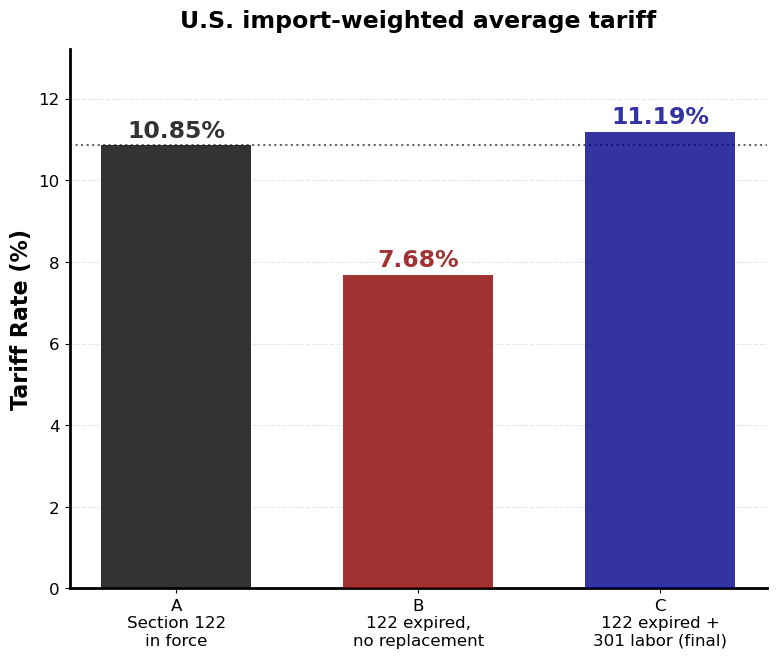

122 in force 10.85%  ->  gap 7.68%  ->  labor 11.19%
net step across the transition: +0.33 pp


In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
order  = ['s122', 'gap', 'final']
labels = ['A\nSection 122\nin force', 'B\n122 expired,\nno replacement',
          'C\n122 expired +\n301 labor (final)']
colors = [PALETTE['s122'], PALETTE['gap'], PALETTE['final']]
vals = [NAT[k] for k in order]
bars = ax.bar(labels, vals, color=colors, width=0.62, zorder=3, alpha=0.8)
for b, v in zip(bars, vals):
    ax.annotate(f'{v:.2f}%', (b.get_x()+b.get_width()/2, v), xytext=(0, 6),
                textcoords='offset points', ha='center', fontsize=17,
                fontweight='bold', color=b.get_facecolor())
ax.axhline(NAT['s122'], color='black', lw=1.5, ls=':', alpha=0.6, zorder=1)
ax.set_ylabel('Tariff Rate (%)'); ax.set_ylim(0, max(vals)*1.18)
ax.set_title('U.S. import-weighted average tariff', fontsize=17, pad=16)
ax.grid(axis='y')
plt.savefig(figfile + 'overview-national-transition.png')
plt.show()
print(f"122 in force {NAT['s122']:.2f}%  ->  gap {NAT['gap']:.2f}%  ->  labor {NAT['final']:.2f}%")
print(f"net step across the transition: {NAT['final']-NAT['s122']:+.2f} pp")

### Who pays more, who pays less

The net move (final labor minus Section 122) is a redistribution. Economies not targeted
by the labor action, USMCA Canada/Mexico (netted to ~0), and CAFTA-DR apparel exporters
get lighter; the 12.5% tier and non-CAFTA suppliers of dutiable goods get heavier.

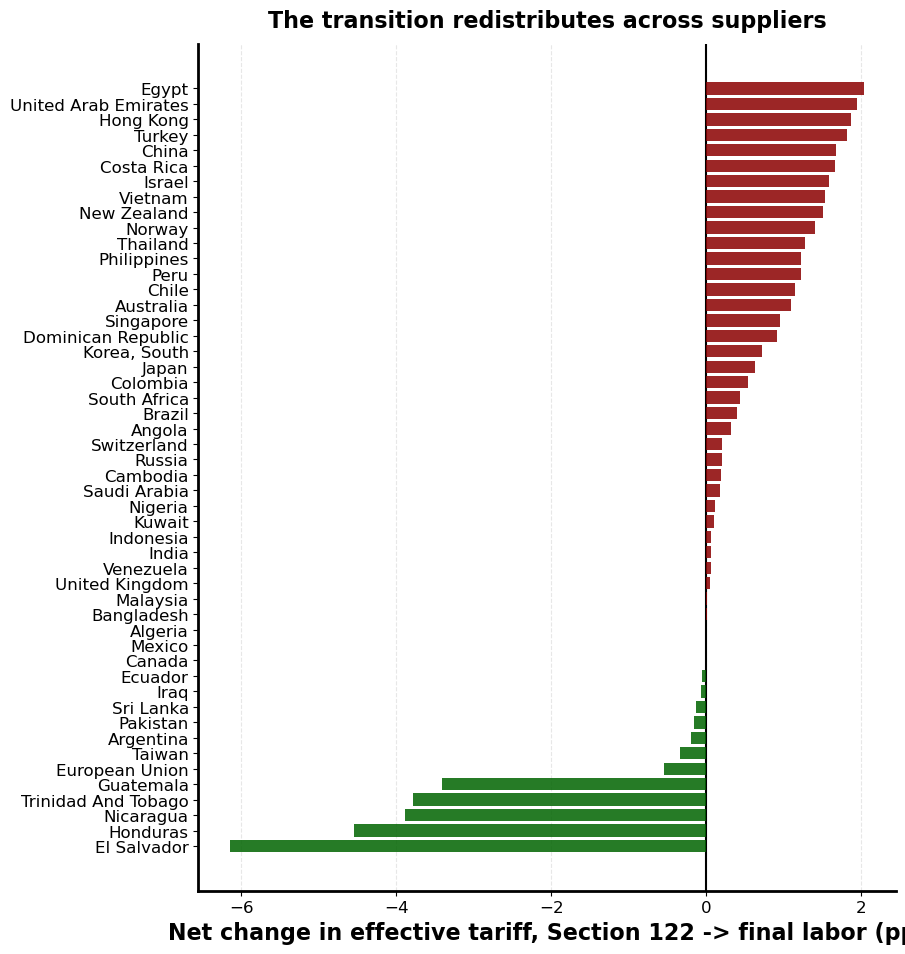

In [7]:
d = S[S.group != 'not targeted'].copy()
d['net'] = d['final'] - d['s122']
d = d.sort_values('net')
fig, ax = plt.subplots(figsize=(9, 11))
cols = [PALETTE['down'] if v < 0 else PALETTE['up'] for v in d['net']]
ax.barh(d['name'], d['net'], color=cols, zorder=3, alpha=0.85)
ax.axvline(0, color='black', lw=1.5)
ax.set_xlabel('Net change in effective tariff, Section 122 -> final labor (pp)')
ax.set_title('The transition redistributes across suppliers', fontsize=16, pad=12)
ax.grid(axis='x')
plt.savefig(figfile + 'overview-redistribution.png')
plt.show()

# Part 2 &mdash; the proposal vs the final action

The final action is **lighter** than the June 5 proposal. Three things changed:

* **Rates.** Six tracked economies fell from 12.5% to 10% (Honduras, India, Pakistan,
  Sri Lanka, Trinidad&nbsp;&&nbsp;Tobago, and the EU).
* **Net-of-MFN cap.** Five economies moved to a cap on MFN&nbsp;+&nbsp;301. The model
  implements it per HS code as `301 = max(0, cap - MFN)` for the four **non-FTA** economies
  (EU, Taiwan, Japan, Switzerland); **Korea keeps the flat cap** because the HTS headings
  override a KORUS claim to the flat rate.
* **Exemptions.** The base list grew from 1,655 to 2,113 codes, and &mdash; the big one
  &mdash; a new **700-code pharmaceutical** exemption was added. The model exempts those
  flat (choice "C"), which pulls down pharma-heavy exporters.

The national average falls from the proposal's level to the final's; the waterfall splits
that fall into the three causes.

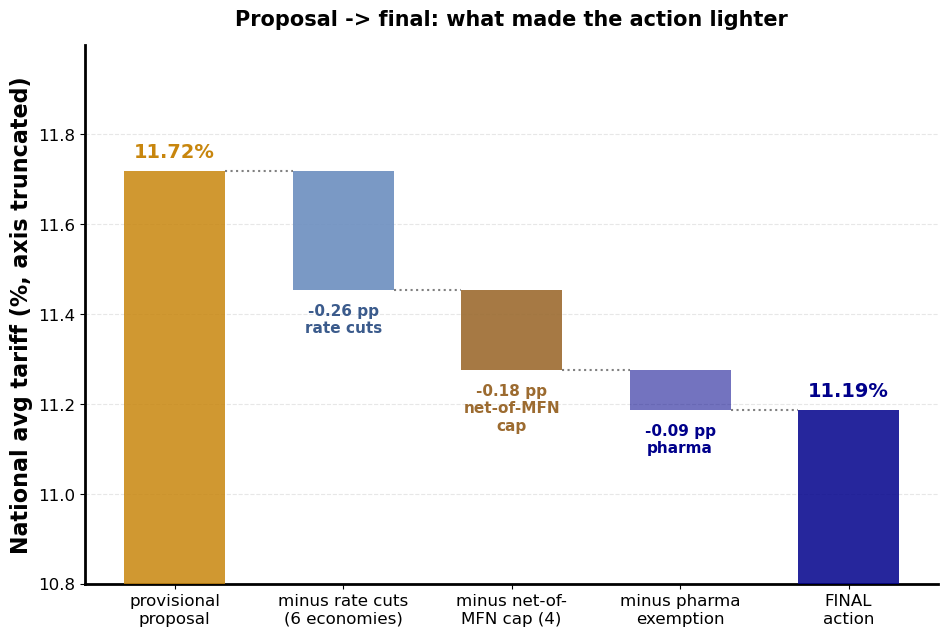

provisional labor national : 11.72%
  rate cuts (6 economies)   : -0.26 pp
  net-of-MFN cap (4 non-FTA): -0.18 pp
  pharma / Part A exemption : -0.09 pp
final labor national       : 11.19%   (-0.53 pp vs proposal)


In [8]:
# Waterfall: the labor levels differ by only ~0.5pp, so a from-zero bar hides the
# change. Zoom the axis and step down: proposal -> rate cuts -> net-of-MFN cap ->
# pharma exemption -> final.
prov, mid, mid2, fin = NAT['prov'], NAT['mid'], NAT['mid2'], NAT['final']
rate_eff, cap_eff, exempt_eff = mid - prov, mid2 - mid, fin - mid2     # all <= 0
base = np.floor(min(prov, mid, mid2, fin) * 10) / 10 - 0.3

fig, ax = plt.subplots(figsize=(11, 7))
ax.bar(0, prov - base, bottom=base, width=0.6, color=PALETTE['prov'],  alpha=0.85, zorder=3)
ax.bar(1, prov - mid,  bottom=mid,  width=0.6, color='#6C8EBF',        alpha=0.90, zorder=3)  # rate drop
ax.bar(2, mid - mid2,  bottom=mid2, width=0.6, color='#9C6B30',        alpha=0.90, zorder=3)  # cap drop
ax.bar(3, mid2 - fin,  bottom=fin,  width=0.6, color=PALETTE['final'], alpha=0.55, zorder=3)  # pharma drop
ax.bar(4, fin - base,  bottom=base, width=0.6, color=PALETTE['final'], alpha=0.85, zorder=3)
for xa, xb, lv in [(0.3, 0.7, prov), (1.3, 1.7, mid), (2.3, 2.7, mid2), (3.3, 3.7, fin)]:
    ax.plot([xa, xb], [lv, lv], ls=':', color='gray', lw=1.5, zorder=2)
ax.text(0, prov + 0.02, f'{prov:.2f}%', ha='center', va='bottom', fontsize=14,
        fontweight='bold', color=PALETTE['prov'])
ax.text(4, fin + 0.02,  f'{fin:.2f}%',  ha='center', va='bottom', fontsize=14,
        fontweight='bold', color=PALETTE['final'])
ax.text(1, mid - 0.03,  f'{rate_eff:+.2f} pp\nrate cuts',    ha='center', va='top',
        fontsize=11, fontweight='bold', color='#3B5B8C')
ax.text(2, mid2 - 0.03, f'{cap_eff:+.2f} pp\nnet-of-MFN\ncap', ha='center', va='top',
        fontsize=11, fontweight='bold', color='#9C6B30')
ax.text(3, fin - 0.03,  f'{exempt_eff:+.2f} pp\npharma',     ha='center', va='top',
        fontsize=11, fontweight='bold', color='darkblue')
ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(['provisional\nproposal', 'minus rate cuts\n(6 economies)',
                    'minus net-of-\nMFN cap (4)', 'minus pharma\nexemption', 'FINAL\naction'])
ax.set_ylabel('National avg tariff (%, axis truncated)')
ax.set_ylim(base, prov + 0.28)
ax.set_title('Proposal -> final: what made the action lighter', fontsize=15, pad=14)
ax.grid(axis='y')
plt.savefig(figfile + 'overview-prov-vs-final-national.png')
plt.show()
print(f"provisional labor national : {prov:.2f}%")
print(f"  rate cuts (6 economies)   : {rate_eff:+.2f} pp")
print(f"  net-of-MFN cap (4 non-FTA): {cap_eff:+.2f} pp")
print(f"  pharma / Part A exemption : {exempt_eff:+.2f} pp")
print(f"final labor national       : {fin:.2f}%   ({fin-prov:+.2f} pp vs proposal)")

### Which economies got lighter, and why

For the biggest targeted suppliers, the labor contribution under the proposal vs the final
action. Two forces show up: the **rate cuts** (Honduras, India, Pakistan, Sri&nbsp;Lanka,
Trinidad, EU drop 2.5pp of headline) and the **pharma exemption** (EU, Switzerland, India,
Japan &mdash; big chemical/pharma exporters &mdash; fall further as chapter-29 codes leave
the base).

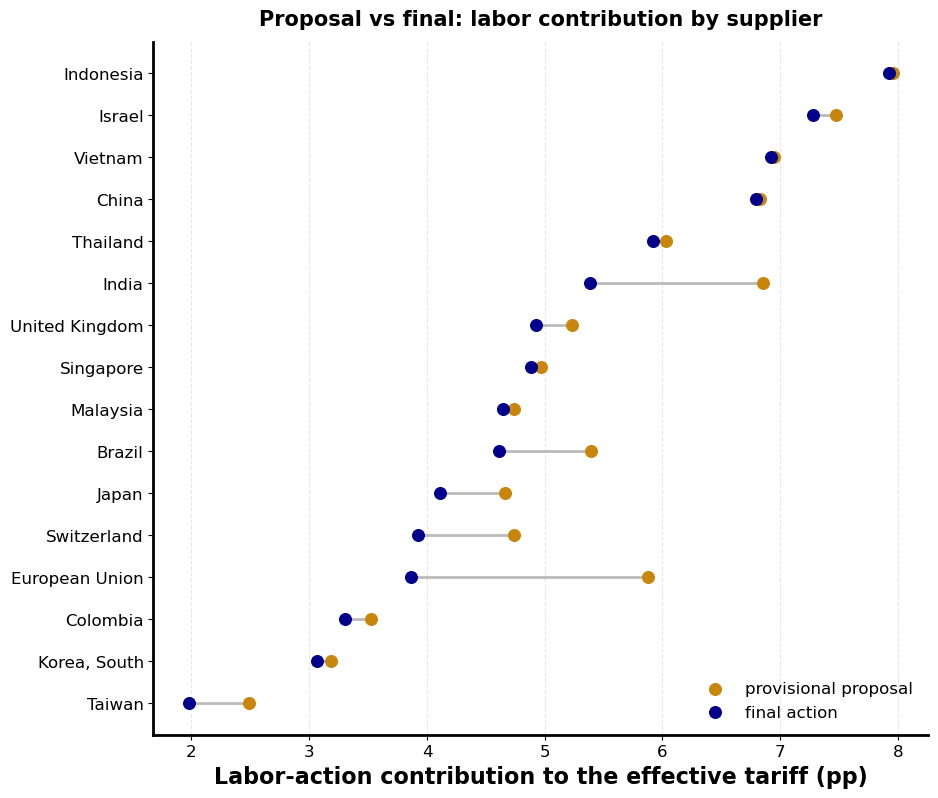

Most-changed economies (proposal -> final), pp:
               name  tier_prov  tier_final prov_contrib final_contrib rate_effect cap_effect exempt_effect  delta
Trinidad And Tobago       12.5        10.0         5.39          0.52       -1.08       0.00         -3.79  -4.86
           Pakistan       12.5        10.0        12.09          9.45       -2.42       0.00         -0.21  -2.63
          Sri Lanka       12.5        10.0        11.29          8.86       -2.26       0.00         -0.17  -2.43
     European Union       12.5        10.0         5.88          3.87       -1.18      -0.69         -0.15  -2.01
              India       12.5        10.0         6.85          5.39       -1.37       0.00         -0.10  -1.47
        Switzerland       12.5        12.5         4.74          3.92        0.00      -0.72         -0.09  -0.81
             Brazil       12.5        12.5         5.40          4.61        0.00       0.00         -0.79  -0.79
              Japan       12.5        12

In [9]:
top = S[(S.group == 'labor target')].nlargest(16, 'imports').sort_values('final_contrib')
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(10, 9))
ax.hlines(y, top['final_contrib'], top['prov_contrib'], color='#BBBBBB', lw=2, zorder=1)
ax.scatter(top['prov_contrib'], y, s=70, color=PALETTE['prov'], zorder=3, label='provisional proposal')
ax.scatter(top['final_contrib'], y, s=70, color=PALETTE['final'], zorder=3, label='final action')
ax.set_yticks(y); ax.set_yticklabels(top['name'])
ax.set_xlabel('Labor-action contribution to the effective tariff (pp)')
ax.set_title('Proposal vs final: labor contribution by supplier', fontsize=15, pad=12)
ax.legend(loc='lower right'); ax.grid(axis='x')
plt.savefig(figfile + 'overview-prov-vs-final-country.png')
plt.show()

# decomposition table for the most-changed economies
tab = S[S.group == 'labor target'].copy()
tab = tab.reindex(tab['delta'].abs().sort_values(ascending=False).index)
show = tab[['name', 'tier_prov', 'tier_final', 'prov_contrib', 'final_contrib',
            'rate_effect', 'cap_effect', 'exempt_effect', 'delta']].head(15)
print("Most-changed economies (proposal -> final), pp:")
print(show.to_string(index=False,
      formatters={c: (lambda x: f'{x:6.2f}') for c in
                  ['prov_contrib','final_contrib','rate_effect','cap_effect','exempt_effect','delta']}))

### The exemption list that changed

The proposal exempted a single **Annex A** (1,655 codes; the model applied only the 1,098
unconditional product codes, mirroring Section 122). The final action's base list is
**Annex II Part A** (2,113 codes) with a new **pharma** scope, and the model now exempts
the unconditional **and** pharma codes (choice C) &mdash; 1,556 in all. Aircraft and Ex
stay taxed in both.

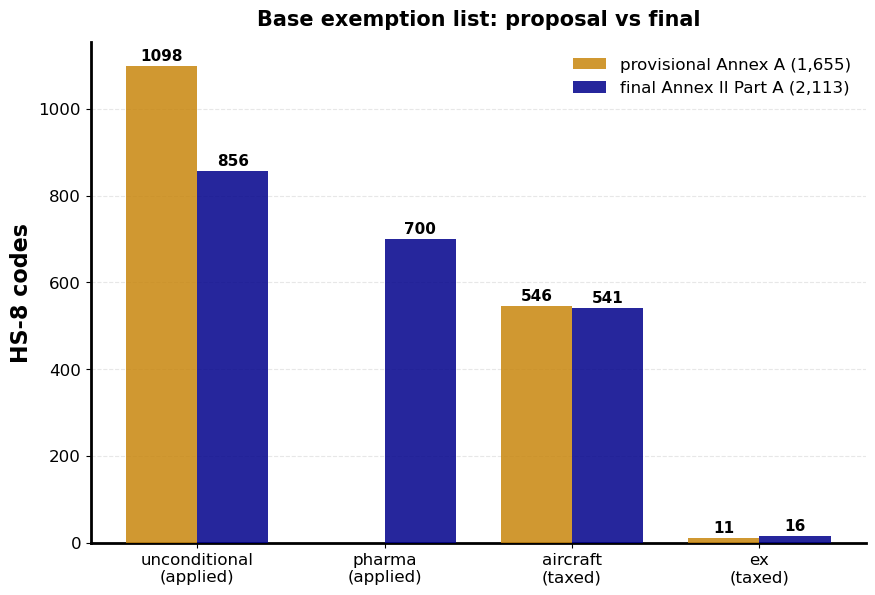

codes the model actually exempts:  provisional 1,098  ->  final 1,556  (+458)
the +700 pharma bucket is the new feature; 363 of those were already
Section-122 product exemptions, 337 are new to the final action.


In [10]:
prov_counts  = {'unconditional\n(applied)': 1098, 'aircraft\n(taxed)': 546, 'ex\n(taxed)': 11}
final_counts = {'unconditional\n(applied)': 856, 'pharma\n(applied)': 700,
                'aircraft\n(taxed)': 541, 'ex\n(taxed)': 16}
cats = ['unconditional\n(applied)', 'pharma\n(applied)', 'aircraft\n(taxed)', 'ex\n(taxed)']
pv = [prov_counts.get(c, 0) for c in cats]
fv = [final_counts.get(c, 0) for c in cats]
x = np.arange(len(cats)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 6.5))
b1 = ax.bar(x - w/2, pv, w, label='provisional Annex A (1,655)', color=PALETTE['prov'], alpha=0.85, zorder=3)
b2 = ax.bar(x + w/2, fv, w, label='final Annex II Part A (2,113)', color=PALETTE['final'], alpha=0.85, zorder=3)
for bars in (b1, b2):
    for b in bars:
        h = b.get_height()
        if h:
            ax.annotate(f'{int(h)}', (b.get_x()+b.get_width()/2, h), xytext=(0, 4),
                        textcoords='offset points', ha='center', fontsize=11, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(cats)
ax.set_ylabel('HS-8 codes'); ax.legend(loc='upper right')
ax.set_title('Base exemption list: proposal vs final', fontsize=15, pad=12)
ax.grid(axis='y')
plt.savefig(figfile + 'overview-exemption-composition.png')
plt.show()
print("codes the model actually exempts:  provisional 1,098  ->  final 1,556  (+458)")
print("the +700 pharma bucket is the new feature; 363 of those were already")
print("Section-122 product exemptions, 337 are new to the final action.")

## Summary

**Section 122 &rarr; labor.** The headline moves little (national ~+0.5pp across the swap),
because the flat 10% surcharge is replaced by a targeted duty with wide carve-outs. But the
*incidence* shifts: 12.5%-tier suppliers of dutiable goods pay more, while non-targeted
economies, USMCA Canada/Mexico, and CAFTA-DR apparel exporters pay less.

**Proposal &rarr; final.** The final action is lighter than the June 5 proposal, for three
reasons the decomposition separates:

1. **Rate cuts** &mdash; six economies from 12.5% to 10%.
2. **The net-of-MFN cap** &mdash; for the four non-FTA economies (EU, Taiwan, Japan,
   Switzerland) the 301 is charged net of each product's column-1 MFN, `max(0, cap - MFN)`.
   Korea keeps the flat cap, because a KORUS claim is overridden to the flat rate.
3. **A new pharmaceutical exemption** &mdash; 700 chapter-29-heavy codes now leave the base
   list, which the model applies flat and which chiefly benefits the EU, Switzerland, India
   and Japan.

**Caveats.** The net-of-MFN cap uses a statutory column-1 MFN per HS code (HTS where the rate
is a clean ad valorem, pooled 2024 customs AVE for specific/compound duties); codes absent from
that table are treated as MFN = 0 (full cap), a small residual upward bias. The pharma exemption
is applied flat, over-exempting non-pharma use of those chemical codes (a small downward bias).
The 13 country-specific Annex II Parts B&ndash;N and the CAFTA/Jordan textile Part O are not
modeled, and the Bangladesh/Cambodia/Indonesia/Malaysia textile TRQs are volume-based and
unmodeled. See the README modeling-limitations section.